# Estimation Plot (Gardner–Altman & Cumming)

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific:* Domain-neutral statistics and research plots: effect sizes, meta-analysis, agreement, omics, replicates and visual inference.

## Design purpose

Shows every observation and, on a second aligned axis, the effect size (difference in means) with its bootstrap sampling distribution and 95% confidence interval. The reader sees how big the effect is and how sure we are, rather than a yes/no p-value. The Gardner–Altman layout compares two groups; the Cumming layout compares several groups against a shared control.

## When to use

- Report an A/B test or experiment where the size of the effect matters more than "significant or not"
- Compare several variants against one control (Cumming layout)
- Replace a bar chart of means plus asterisks in a report or paper

## Avoid when

- The audience only needs the headline number (state the effect and CI in text)
- Groups are paired or repeated measures without showing the pairing (use a paired estimation plot)
- There are so many observations that the swarm becomes a solid block (show a density or box instead)

## Alternatives

- Points + 95% CI (error_bar_ci)
- Forest plot (many effects)
- Raincloud plot

## Design tips

- What it fixes: a bar of means with a p-value hides the data and reduces the result to a binary verdict; the estimation plot shows the data, the effect size and its precision
- Anchor the difference axis so that zero lines up with the control mean; the effect then reads as a distance
- Use a bootstrap (5,000+ resamples) for the CI so skewed data need no normality assumption
- Python implementation of the original method — DABEST (`pip install dabest`)

## Example

A simulated A/B test of four onboarding flows in a trading app (60 new customers each), measuring first-month deposits. Left: the current flow vs. Flow A (Gardner–Altman). Right: all three new flows vs. the current one (Cumming).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import seaborn as sns
from scipy.stats import gaussian_kde

### Data

In [2]:
rng = np.random.default_rng(2019)
means = {"Current": 410, "Flow A": 455, "Flow B": 425, "Flow C": 500}
groups = list(means)
df = pd.concat([pd.DataFrame({"group": g, "deposit": rng.gamma(9, m / 9, 60)}) for g, m in means.items()],
               ignore_index=True)


def boot_diff(a, b, n=5000, seed=0):
    """Bootstrap distribution of mean(b) - mean(a)."""
    r = np.random.default_rng(seed)
    return (b[r.integers(0, len(b), (n, len(b)))].mean(1)
            - a[r.integers(0, len(a), (n, len(a)))].mean(1))


values = {g: df.loc[df["group"] == g, "deposit"].to_numpy() for g in groups}
ctrl = values[groups[0]]
diffs = {g: boot_diff(ctrl, values[g], seed=i) for i, g in enumerate(groups[1:])}
df.groupby("group", sort=False)["deposit"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Current,60.0,392.0,132.0,152.0,289.0,385.0,449.0,708.0
Flow A,60.0,477.0,144.0,188.0,370.0,467.0,568.0,853.0
Flow B,60.0,418.0,138.0,166.0,325.0,397.0,460.0,863.0
Flow C,60.0,511.0,174.0,145.0,397.0,498.0,602.0,939.0


### Plot

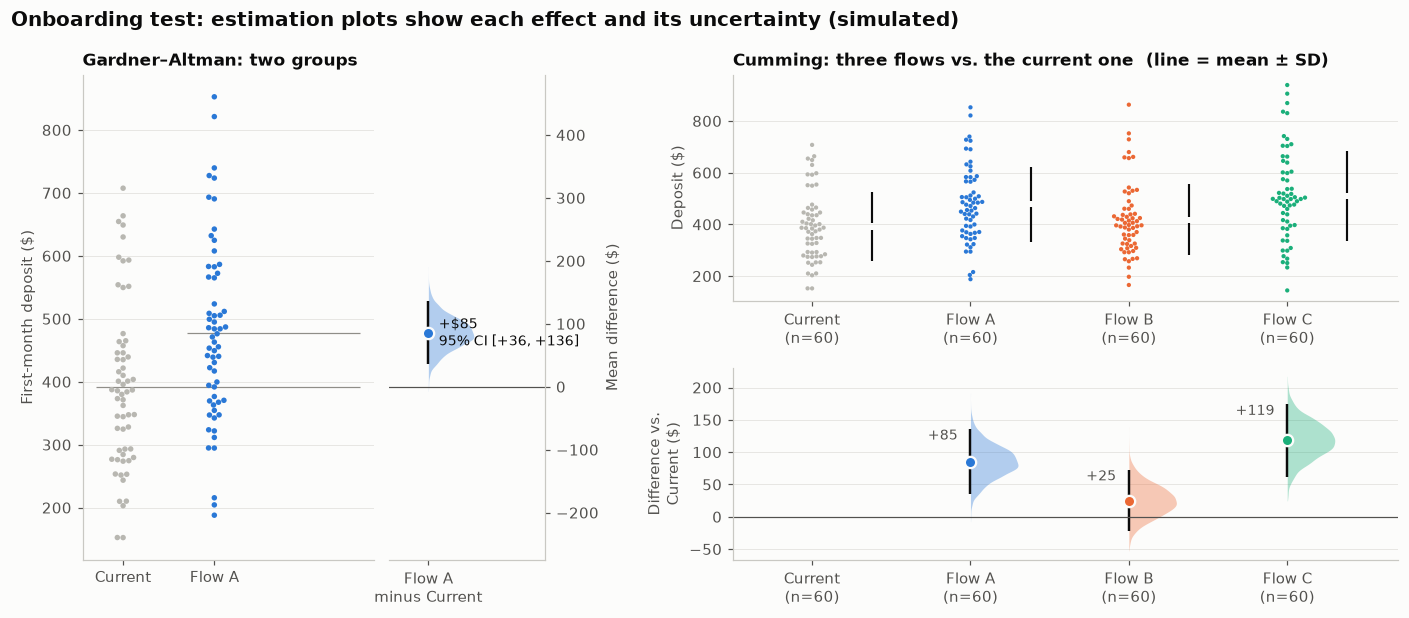

In [3]:
colors = [GRAY] + PALETTE[:3]
fig = plt.figure(figsize=(13, 5.8))
gs = fig.add_gridspec(2, 4, width_ratios=[1.4, 0.75, 0.75, 3.2], height_ratios=[1, 0.85],
                      hspace=0.32, wspace=0.05)


def half_violin(ax, x, d, color, width=0.35):
    grid = np.linspace(d.min(), d.max(), 200)
    dens = gaussian_kde(d)(grid)
    ax.fill_betweenx(grid, x, x + dens / dens.max() * width, color=color, alpha=0.35, linewidth=0)
    lo, hi = np.percentile(d, [2.5, 97.5])
    obs = d.mean()
    ax.vlines(x, lo, hi, color="#0b0b0b", linewidth=1.6)
    ax.scatter([x], [obs], s=55, color=color, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    return obs, lo, hi


# Gardner–Altman: two groups + floating difference axis
a1 = fig.add_subplot(gs[:, 0])
two = df[df["group"].isin(groups[:2])]
sns.swarmplot(data=two, x="group", y="deposit", hue="group", palette=colors[:2], size=3.6, ax=a1, legend=False)
m0, m1 = ctrl.mean(), values[groups[1]].mean()
for x, m in ((0, m0), (1, m1)):
    a1.hlines(m, x - 0.3, 2.6, color="#8f8e88", linewidth=0.8, clip_on=False, zorder=0)
a1.set_xlabel("")
a1.set_ylabel("First-month deposit ($)")
a1.set_title("Gardner–Altman: two groups", fontsize=11)
a1.grid(axis="x", visible=False)

a2 = fig.add_subplot(gs[:, 1])
lo_y, hi_y = a1.get_ylim()
a2.set_ylim(lo_y - m0, hi_y - m0)  # zero on the difference axis = control mean
obs, lo, hi = half_violin(a2, 0, diffs[groups[1]], PALETTE[0])
a2.axhline(0, color="#52514e", linewidth=0.8)
a2.text(0.08, obs, f"+${obs:.0f}\n95% CI [{lo:+.0f}, {hi:+.0f}]", fontsize=9, va="center")
a2.set_xlim(-0.3, 0.9)
a2.set_xticks([0], [f"{groups[1]}\nminus {groups[0]}"])
a2.yaxis.tick_right()
a2.yaxis.set_label_position("right")
a2.set_ylabel("Mean difference ($)")
a2.spines["left"].set_visible(False)
a2.spines["right"].set_visible(True)
a2.grid(False)

# Cumming: several groups vs. a shared control
a3 = fig.add_subplot(gs[0, 3])
sns.swarmplot(data=df, x="group", y="deposit", hue="group", palette=colors, size=2.8, ax=a3,
              order=groups, legend=False)
gap = 0.015 * (df["deposit"].max() - df["deposit"].min())
for x, g in enumerate(groups):  # Cumming style: mean ± SD as a gapped line beside each swarm
    m, s = values[g].mean(), values[g].std(ddof=1)
    a3.vlines([x + 0.38] * 2, [m - s, m + gap], [m - gap, m + s], color="#0b0b0b", linewidth=1.4)
a3.set_xlabel("")
a3.set_xticks(range(len(groups)), [""] * len(groups))
a3.set_ylabel("Deposit ($)")
a3.set_title("Cumming: three flows vs. the current one  (line = mean ± SD)", fontsize=11)
a3.grid(axis="x", visible=False)

a4 = fig.add_subplot(gs[1, 3], sharex=a3)
for x, g in enumerate(groups[1:], start=1):
    o, l, h = half_violin(a4, x, diffs[g], colors[x], width=0.3)
    a4.text(x - 0.08, h, f"{o:+.0f}", ha="right", va="top", fontsize=9, color="#52514e")
a4.axhline(0, color="#52514e", linewidth=0.8)
a4.set_xticks(range(len(groups)), [f"{g}\n(n={len(values[g])})" for g in groups])
a4.set_ylabel(f"Difference vs.\n{groups[0]} ($)")
a4.grid(axis="x", visible=False)
a4.set_xlim(-0.5, len(groups) - 0.3)

fig.suptitle("Onboarding test: estimation plots show each effect and its uncertainty (simulated)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.subplots_adjust(left=0.06, right=0.98, top=0.88, bottom=0.12)
plt.show()

## How to read it

In the left panel, the dot on the right-hand axis is the extra deposit per customer for Flow A, and its vertical line is the 95% CI. The shaded curve shows the bootstrap distribution. Zero on that axis lines up with the current flow's mean. On the right, each new flow's effect sits below its customers: Flow C's whole CI is above zero, while Flow B's CI straddles zero, so its effect could be nothing.

## Reference

This method comes from the research literature:

- Ho, J., Tumkaya, T., Aryal, S., Choi, H. & Claridge-Chang, A. (2019). Moving beyond P values: data analysis with estimation graphics. Nature Methods 16, 565–566. <https://doi.org/10.1038/s41592-019-0470-3>

---
Standalone script: [`estimation_plot.py`](estimation_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)